# Week 7 - Milestone One week

# 1. Lesson: no lesson this week.  Milestone One is due!

# 2. Weekly graph question

Below are the graphs from last week's weekly graph question.  Suppose you wanted to cause the viewer to examine the last three months of data first.  How could you use preattentive attributes to do that?  Suggest several possibilities.

In [3]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

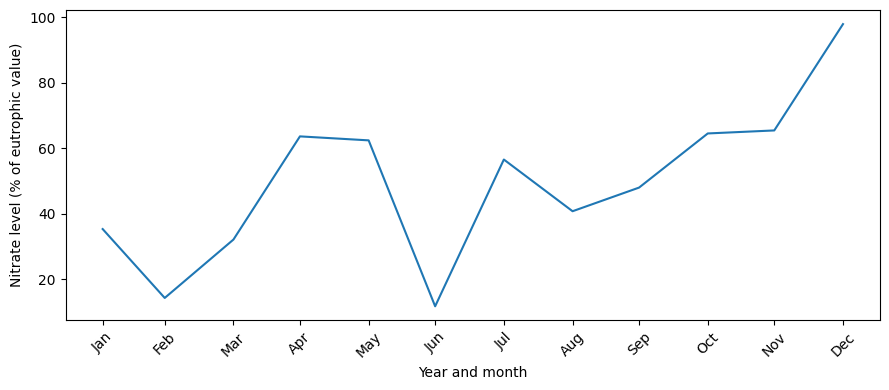

In [4]:
numdates = 12
np.random.seed(0)
time_series = 100 * (np.random.normal(size=numdates) / 5 + np.arange(numdates) / 16)
datearray = pd.date_range(start='2023/01/01', periods=numdates, freq='ME')

plt.figure(figsize=(9, 4))
ax = sns.lineplot(x=datearray, y=time_series)
ax.set_xlabel('Year and month')
ax.set_ylabel('Nitrate level (% of eutrophic value)')
ax.set_xticks(datearray)
ax.set_xticklabels(datearray.strftime('%b'), rotation=45)
plt.tight_layout()
plt.show()

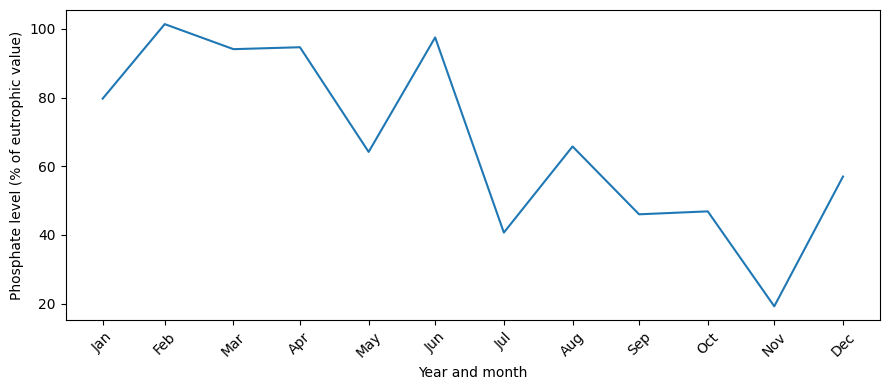

In [5]:
np.random.seed(1)
time_series = 100 * (1 - (np.random.normal(size=numdates) / 8 + np.arange(numdates) / 16))
datearray = pd.date_range(start='2023/01/01', periods=numdates, freq='ME')

plt.figure(figsize=(9, 4))
ax = sns.lineplot(x=datearray, y=time_series)
ax.set_xlabel('Year and month')
ax.set_ylabel('Phosphate level (% of eutrophic value)')
ax.set_xticks(datearray)
ax.set_xticklabels(datearray.strftime('%b'), rotation=45)
plt.tight_layout()
plt.show()

I would use a different color for the last three months (October, November, and December) and make the earlier months light gray. I could also make the last part of the line thicker, add larger dots, and show the values next to those dots. Another option is to add a light background behind the last three months. These changes would help people notice the recent results first without changing the data.

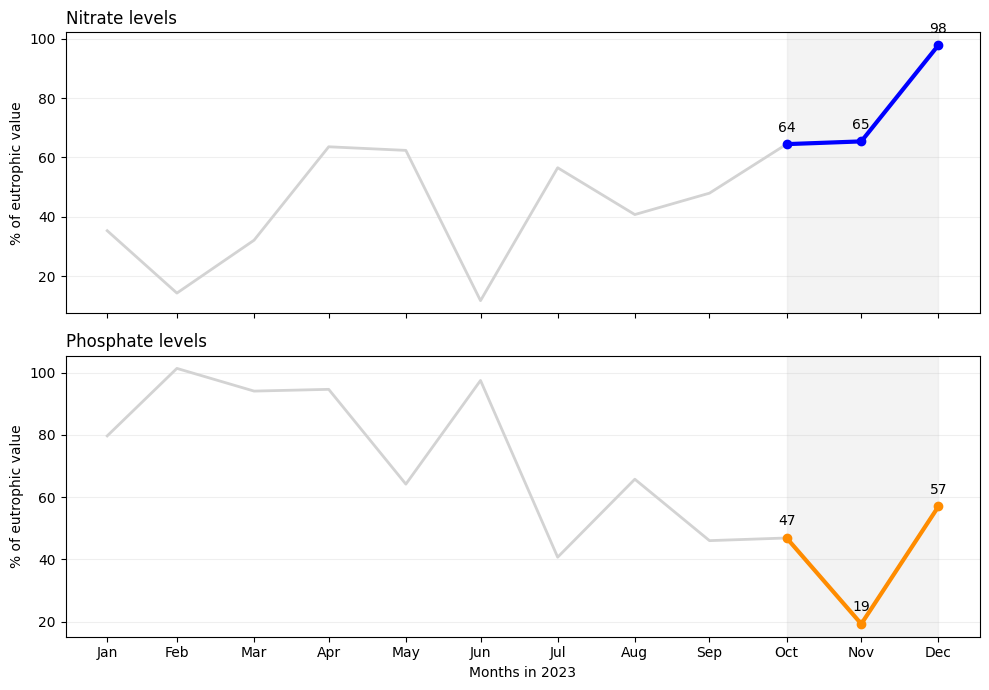

In [6]:
months = pd.date_range(start='2023/01/01', periods=12, freq='ME')

np.random.seed(0)
nitrate = 100 * (np.random.normal(size=12) / 5 + np.arange(12) / 16)

np.random.seed(1)
phosphate = 100 * (1 - (np.random.normal(size=12) / 8 + np.arange(12) / 16))

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

for ax, values, name, color in [
    (axes[0], nitrate, 'Nitrate levels', 'blue'),
    (axes[1], phosphate, 'Phosphate levels', 'darkorange')
]:
    ax.plot(months, values, color='lightgray', linewidth=2)
    ax.plot(months[-3:], values[-3:], color=color, linewidth=3, marker='o')
    ax.axvspan(months[-3], months[-1], color='lightgray', alpha=0.25)
    ax.set_title(name, loc='left')
    ax.set_ylabel('% of eutrophic value')
    ax.grid(axis='y', alpha=0.2)

    for date, value in zip(months[-3:], values[-3:]):
        ax.annotate(f'{value:.0f}', (date, value),
                    xytext=(0, 9), textcoords='offset points', ha='center')

axes[1].set_xlabel('Months in 2023')
axes[1].set_xticks(months)
axes[1].set_xticklabels(months.strftime('%b'))
plt.tight_layout()
plt.show()

# 3. Working on your chosen project datasets

This week, you can work on Milestone One rather than having a particular exercise about working on your datasets

# 4. Storytelling With Data plot

Reproduce any graph of your choice in p. 99-119 of the Storytelling With Data book as best you can. (The first half of chapter four). You do not have to get the exact data values right, just the overall look and feel.

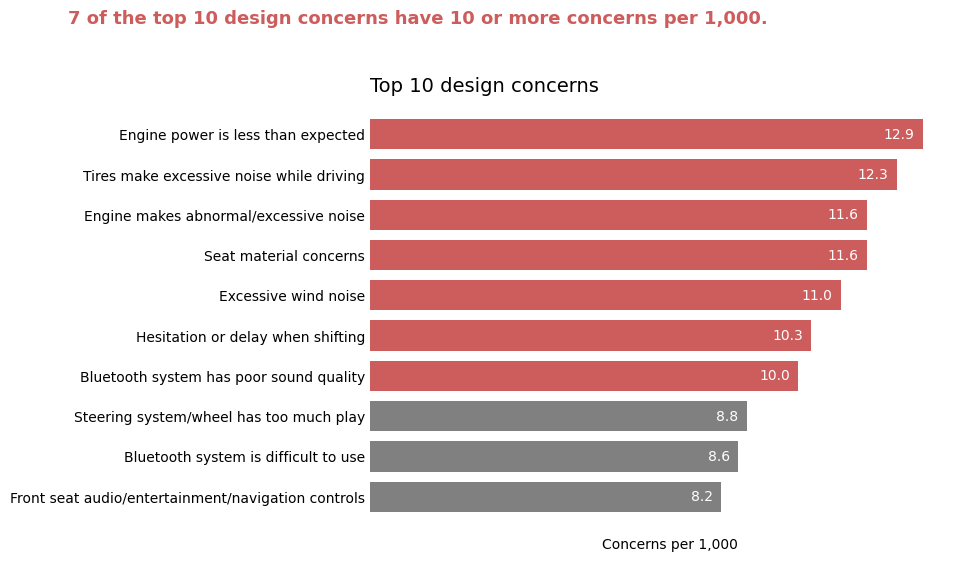

In [7]:
concerns = [
    'Engine power is less than expected',
    'Tires make excessive noise while driving',
    'Engine makes abnormal/excessive noise',
    'Seat material concerns',
    'Excessive wind noise',
    'Hesitation or delay when shifting',
    'Bluetooth system has poor sound quality',
    'Steering system/wheel has too much play',
    'Bluetooth system is difficult to use',
    'Front seat audio/entertainment/navigation controls'
]
values = [12.9, 12.3, 11.6, 11.6, 11.0, 10.3, 10.0, 8.8, 8.6, 8.2]

bar_colors = ['indianred' if value >= 10 else 'gray' for value in values]

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(concerns, values, color=bar_colors, height=0.75)
ax.invert_yaxis()   # Biggest values appear at the top
ax.set_xlim(0, 14)

for bar, value in zip(bars, values):
    ax.text(value - 0.2, bar.get_y() + bar.get_height() / 2,
            f'{value:.1f}', ha='right', va='center', color='white')

ax.set_title('Top 10 design concerns', loc='left', fontsize=14)
ax.set_xlabel('Concerns per 1,000')
ax.set_xticks([])   # Hide numbers along the bottom
ax.tick_params(axis='y', length=0)

for side in ['top', 'right', 'bottom', 'left']:
    ax.spines[side].set_visible(False)

plt.suptitle('7 of the top 10 design concerns have 10 or more concerns per 1,000.',
             color='indianred', fontsize=13, fontweight='bold', y=0.99)
plt.subplots_adjust(left=0.46, right=0.96, top=0.84, bottom=0.12)
plt.show()

I recreated Figure 4.8, 'Leverage color to draw attention" from page 111